# U.S. Flight Delay & Cancellation Analysis

Analyzing flight delays, cancellation causes, airport bottlenecks, and airline performances using BigQuery flight datasets.

In [2]:
from google.colab import auth
auth.authenticate_user()
from google.cloud import bigquery
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

## 1. Data Loading & Initialization
Connecting to BigQuery and loading raw datasets into pandas DataFrames.

In [3]:
client = bigquery.Client(project="airplane-delay-analysis")
P = "airplane-delay-analysis.flight_analysis"

def load(table):
    d = client.query(f"SELECT * FROM `{P}.{table}`").to_dataframe()
    for c in d.columns:
        if str(d[c].dtype) in ("Int64", "Float64"):
            d[c] = d[c].astype("float64")
    return d

flights  = load("flight_sample_clean")
daily    = load("daily_airport_stats_clean")
airports = load("airports_clean")
airlines = load("airlines_clean")

flights["flight_date"] = pd.to_datetime(flights["flight_date"])
daily["flight_date"]   = pd.to_datetime(daily["flight_date"])

for name, d in [("flights", flights), ("daily", daily), ("airports", airports), ("airlines", airlines)]:
    print(name, d.shape)

flights (500000, 38)
daily (202872, 14)
airports (360, 11)
airlines (14, 8)


## 2. Global Metric Preparation
Filtering out cancelled and diverted flights to create a clean baseline of completed flights.

In [4]:
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)
os.makedirs("figures", exist_ok=True)

# completed flights only (for delay measures)
done = flights[(flights["cancelled"] == 0) & (flights["diverted"] == 0)].copy()
done["sched_hour"] = (done["sched_dep_time"] // 100) % 24
print(done.shape, done["arr_del15"].mean())

(489636, 39) 0.228136820005065


## 3. Delays by Month & Hour of Day
Plotting flight delay rates over the months of the year and across different hours of the day.

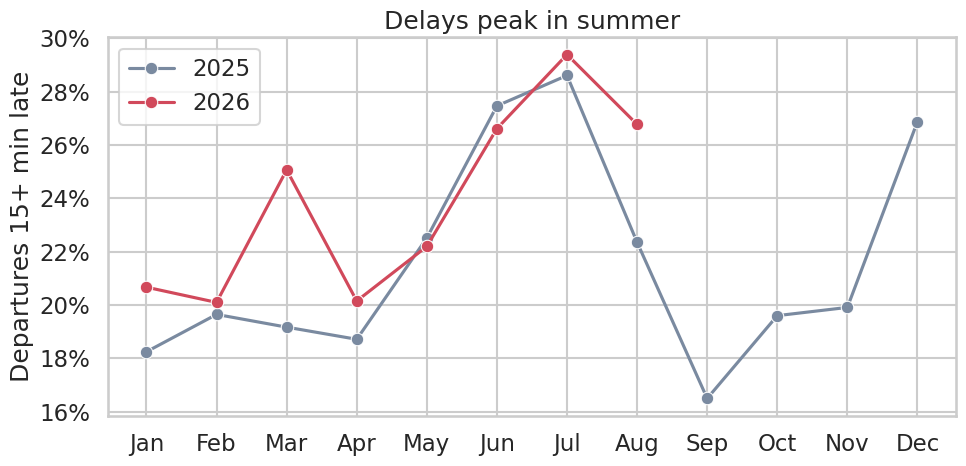

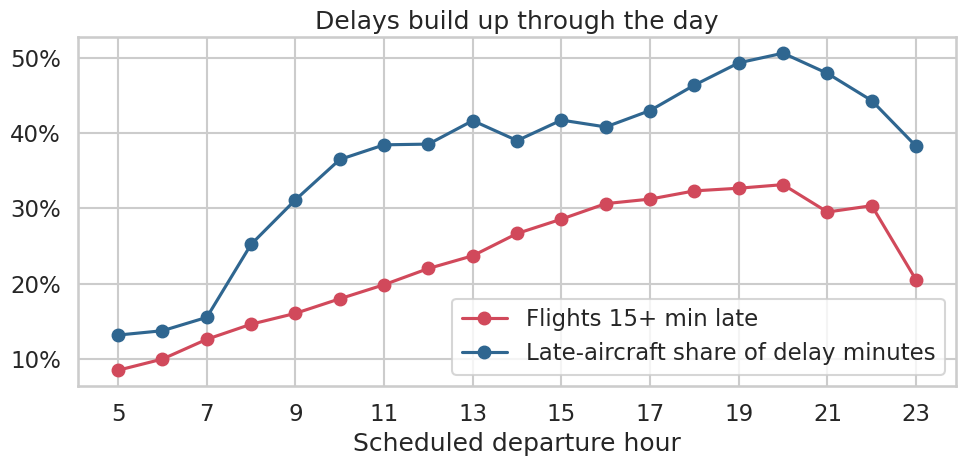

In [5]:
daily["yr"] = daily["flight_date"].dt.year
daily["mo"] = daily["flight_date"].dt.month
daily["w"] = daily["departures_scheduled"] - daily["cancelled"]
daily["late"] = daily["dep_del15_rate"] * daily["w"]
daily["w_valid"] = daily["w"].where(daily["dep_del15_rate"].notna(), 0)

m = daily.groupby(["yr", "mo"]).agg(late=("late", "sum"), w=("w_valid", "sum")).reset_index()
m["rate"] = m["late"] / m["w"]

fig, ax = plt.subplots()
sns.lineplot(data=m, x="mo", y="rate", hue="yr", marker="o", palette=["#7a8aa0", "#d1495b"], ax=ax)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="", ylabel="Departures 15+ min late", title="Delays peak in summer")
ax.legend(title="")
plt.tight_layout(); plt.savefig("figures/01_monthly_delay_rate.png", dpi=200); plt.show()

hr = done[done["sched_hour"].between(5, 23)].copy()
cause_cols = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
hr["cause_total"] = hr[cause_cols].sum(axis=1)

h = hr.groupby("sched_hour").agg(
    delay_rate=("arr_del15", "mean"),
    late_ac=("late_aircraft_delay", "sum"),
    cause_total=("cause_total", "sum"),
).reset_index()
h["late_aircraft_share"] = h["late_ac"] / h["cause_total"]

fig, ax = plt.subplots()
ax.plot(h["sched_hour"], h["delay_rate"], marker="o", color="#d1495b", label="Flights 15+ min late")
ax.plot(h["sched_hour"], h["late_aircraft_share"], marker="o", color="#2f6690", label="Late-aircraft share of delay minutes")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="Scheduled departure hour", ylabel="", title="Delays build up through the day")
ax.legend()
ax.set_xticks(range(5, 24, 2))
plt.tight_layout(); plt.savefig("figures/02_delay_by_hour.png", dpi=200); plt.show()

## 4. Most-Delayed Airports & Airlines
Calculating and ranking the airports and airlines with the highest percentage of delayed flights.

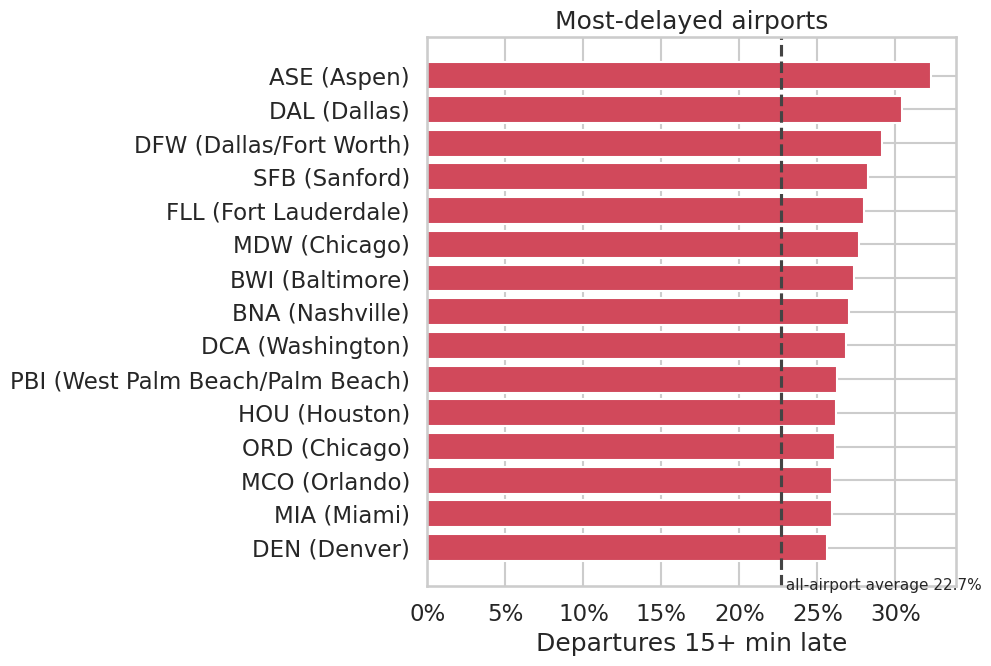

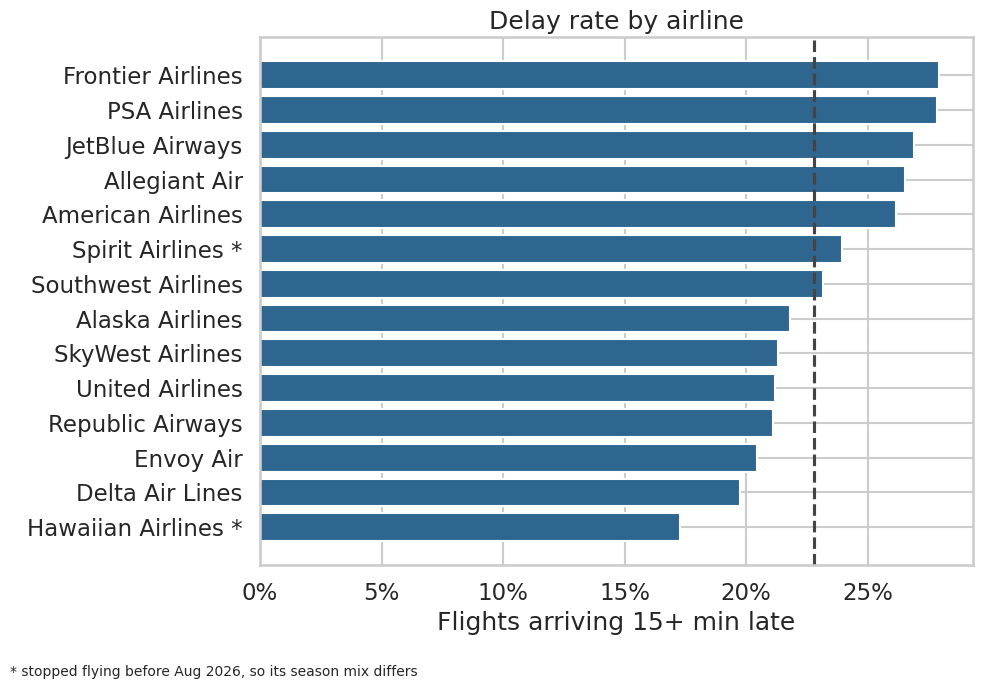

In [6]:
a = daily.groupby("airport").agg(
    scheduled=("departures_scheduled", "sum"),
    late=("late", "sum"),
    w=("w_valid", "sum"),
).reset_index()
a["rate"] = a["late"] / a["w"]
a = a[a["scheduled"] >= 10000].merge(
    airports[["iata_code", "city_name"]], left_on="airport", right_on="iata_code", how="left"
)
a["label"] = a["airport"] + " (" + a["city_name"] + ")"
top = a.sort_values("rate", ascending=False).head(15).iloc[::-1]

baseline = daily["late"].sum() / daily["w_valid"].sum()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["label"], top["rate"], color="#d1495b")
ax.axvline(baseline, color="#444", linestyle="--")
ax.text(baseline, -0.9, f" all-airport average {baseline:.1%}", fontsize=11, va="top")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="Departures 15+ min late", ylabel="", title="Most-delayed airports")
plt.tight_layout(); plt.savefig("figures/03_worst_airports.png", dpi=200); plt.show()

al = done.groupby(["airline_code", "airline"]).agg(
    flights=("arr_del15", "size"), rate=("arr_del15", "mean")
).reset_index()
# airlines that did not fly the whole period are marked with *
partial = airlines.loc[~airlines["still_operating"], "airline_code"].tolist()
al["label"] = al["airline"] + np.where(al["airline_code"].isin(partial), " *", "")
al = al.sort_values("rate")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(al["label"], al["rate"], color="#2f6690")
ax.axvline(done["arr_del15"].mean(), color="#444", linestyle="--")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="Flights arriving 15+ min late", ylabel="", title="Delay rate by airline")
fig.text(0.01, 0.01, "* stopped flying before Aug 2026, so its season mix differs", fontsize=10)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig("figures/04_airline_delay_rate.png", dpi=200); plt.show()

## 5. Delay Minutes by Primary Cause
Breaking down total flight delay minutes into categories to identify the primary drivers of delays.

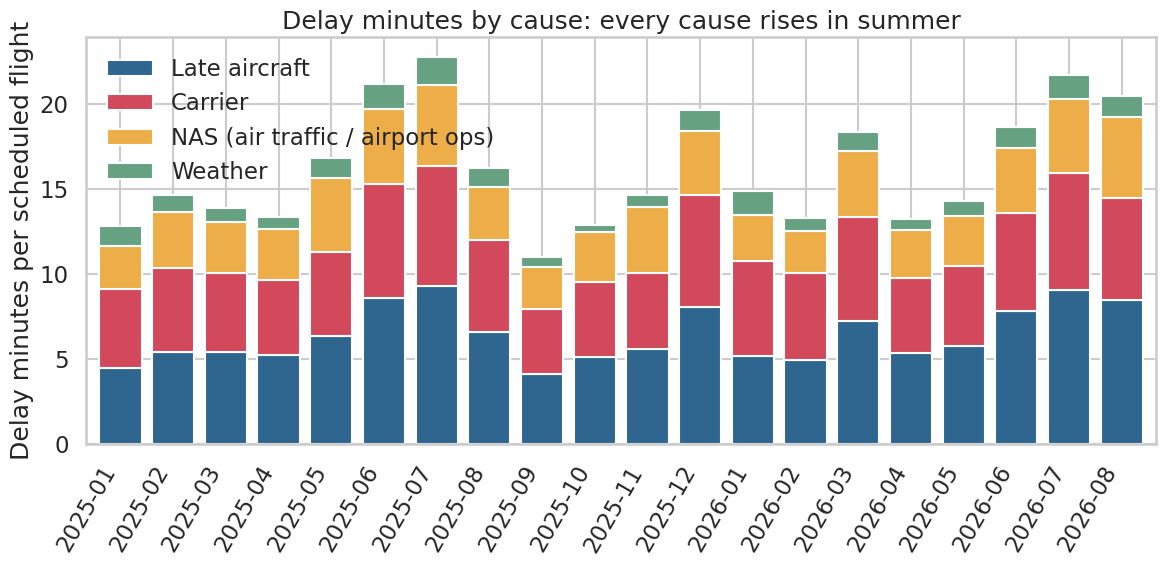

In [7]:
d = daily.copy()
d["ym"] = d["flight_date"].dt.to_period("M").astype(str)
g = d.groupby("ym").agg(
    flights=("departures_scheduled", "sum"),
    late_aircraft=("late_aircraft_delay_minutes", "sum"),
    carrier=("carrier_delay_minutes", "sum"),
    nas=("nas_delay_minutes", "sum"),
    weather=("weather_delay_minutes", "sum"),
)
per = g[["late_aircraft", "carrier", "nas", "weather"]].div(g["flights"], axis=0)

ax = per.plot(kind="bar", stacked=True, figsize=(12, 6),
              color=["#2f6690", "#d1495b", "#edae49", "#66a182"], width=0.8)
ax.set(xlabel="", ylabel="Delay minutes per scheduled flight",
       title="Delay minutes by cause: every cause rises in summer")
ax.legend(["Late aircraft", "Carrier", "NAS (air traffic / airport ops)", "Weather"],
          frameon=False, loc="upper left")
plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.savefig("figures/05_delay_causes_by_month.png", dpi=200); plt.show()

## 6. Traffic Volume vs. Delay Rate
Correlating total airport flight volume with average delay rates to see if busier airports experience more delays.

correlation (log volume vs delay rate): 0.38 | airports: 131


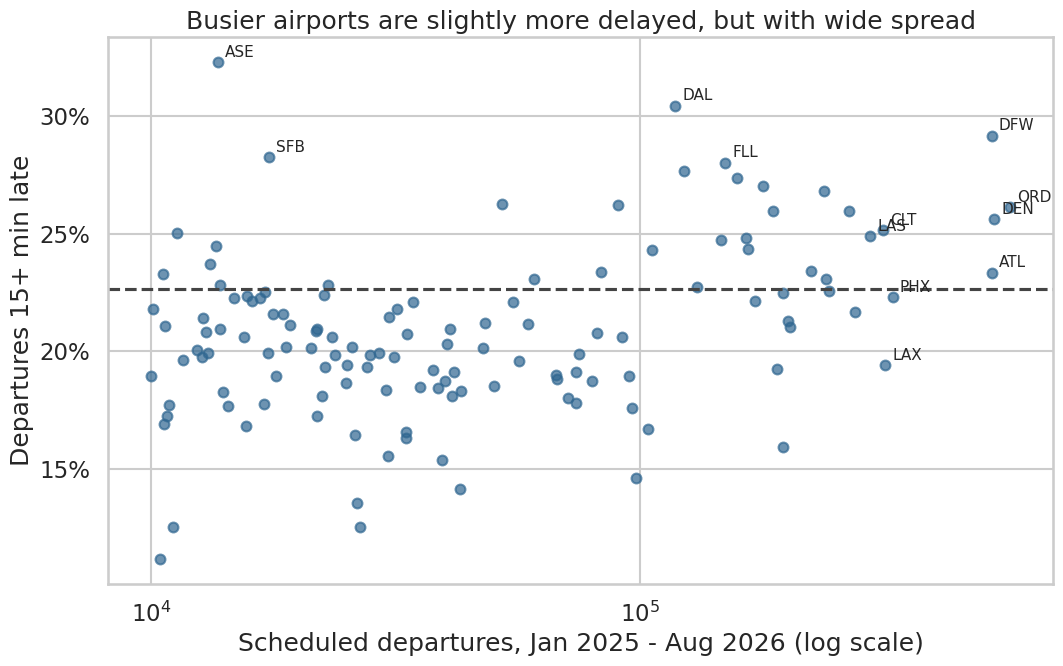

In [8]:
ap = daily.groupby("airport").agg(
    scheduled=("departures_scheduled", "sum"),
    late=("late", "sum"), w=("w_valid", "sum")).reset_index()
ap["rate"] = ap["late"] / ap["w"]
ap = ap[ap["scheduled"] >= 10000]

corr = np.corrcoef(np.log10(ap["scheduled"]), ap["rate"])[0, 1]
print("correlation (log volume vs delay rate):", round(corr, 2), "| airports:", len(ap))

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(ap["scheduled"], ap["rate"], s=50, color="#2f6690", alpha=0.7)
ax.set_xscale("log")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.axhline(daily["late"].sum() / daily["w_valid"].sum(), color="#444", linestyle="--")

# label the 8 busiest and the 5 most delayed airports
lab = pd.concat([ap.nlargest(8, "scheduled"), ap.nlargest(5, "rate")]).drop_duplicates("airport")
for _, r in lab.iterrows():
    ax.annotate(r["airport"], (r["scheduled"], r["rate"]), xytext=(5, 4),
                textcoords="offset points", fontsize=11)

ax.set(xlabel="Scheduled departures, Jan 2025 - Aug 2026 (log scale)",
       ylabel="Departures 15+ min late",
       title="Busier airports are slightly more delayed, but with wide spread")
plt.tight_layout(); plt.savefig("figures/06_volume_vs_delay.png", dpi=200); plt.show()

## 7. Cancellation Trends & Root Causes
Analyzing monthly cancellation rates and identifying the primary official reasons for cancelled flights.

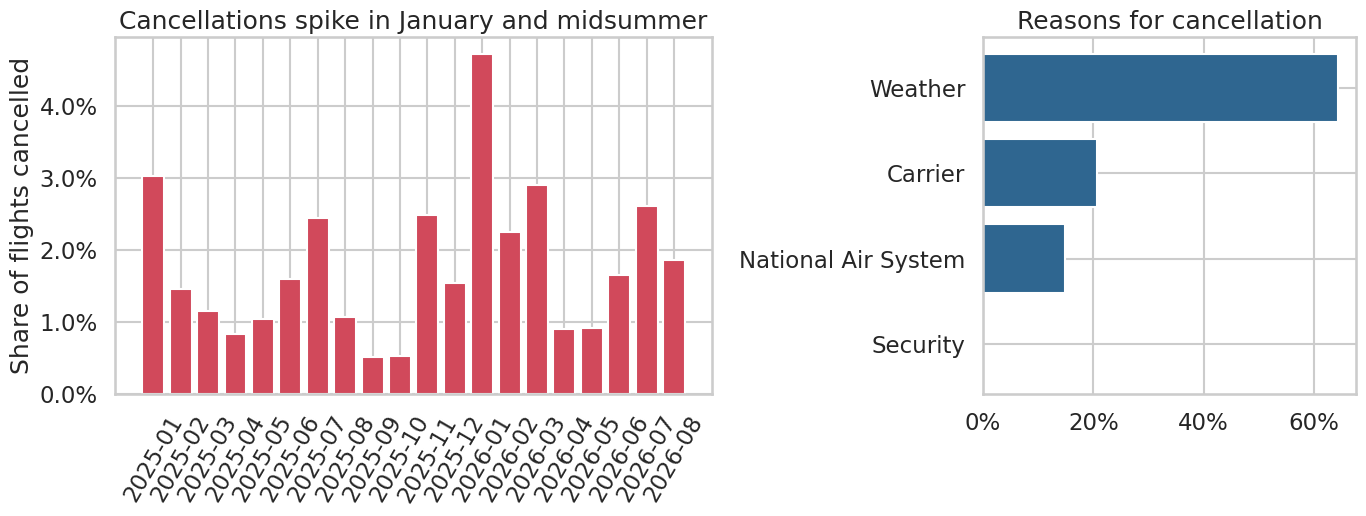

8884.0 cancelled flights in the sample


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

# left: monthly cancel rate (full data)
cm = d.groupby("ym").agg(c=("cancelled", "sum"), s=("departures_scheduled", "sum"))
cm["rate"] = cm["c"] / cm["s"]
axes[0].bar(cm.index, cm["rate"], color="#d1495b")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set(title="Cancellations spike in January and midsummer", ylabel="Share of flights cancelled")

# right: why flights were cancelled (sample)
why = flights.loc[flights["cancelled"] == 1, "cancellation_reason"].value_counts(normalize=True).sort_values()
axes[1].barh(why.index, why.values, color="#2f6690")
axes[1].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[1].set(title="Reasons for cancellation")

plt.tight_layout(); plt.savefig("figures/07_cancellations.png", dpi=200); plt.show()
print(flights["cancelled"].sum(), "cancelled flights in the sample")

## 8. Delay Rates by Flight Direction & Distance
Comparing delay rates based on travel direction and flight distance bands.

             size    mean
direction                
Eastbound  245343  0.2246
Westbound  244293  0.2317
             size    mean
dist_band                
<500       164697  0.2208
500-1000   177464  0.2317
1000-1500   81226  0.2387
1500-2000   34232  0.2327
>2000       31993  0.2148


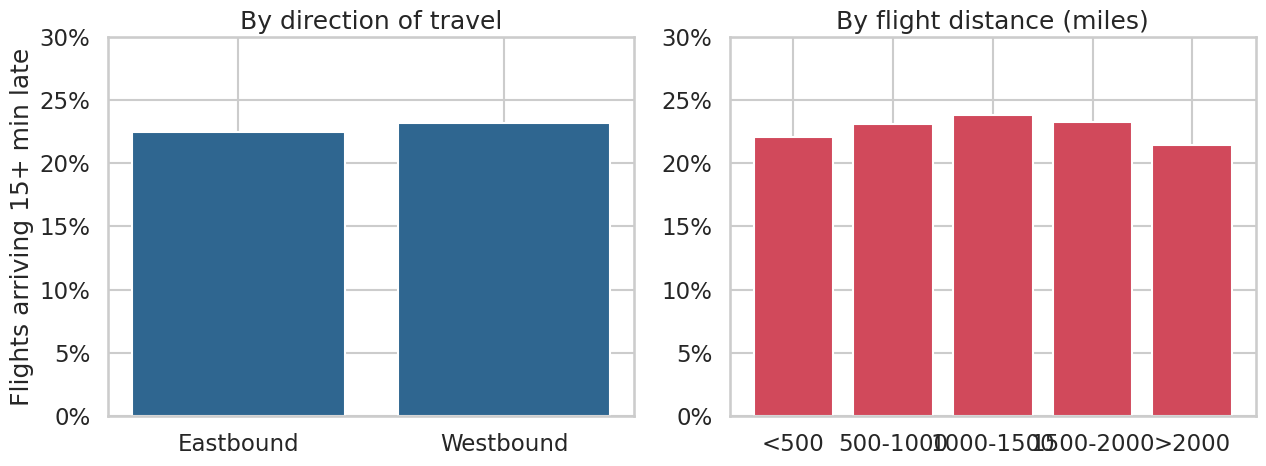

In [10]:
ap = airports[["iata_code", "longitude"]]
x = (done
     .merge(ap.rename(columns={"iata_code": "origin", "longitude": "o_lon"}), on="origin")
     .merge(ap.rename(columns={"iata_code": "dest", "longitude": "d_lon"}), on="dest"))
x["direction"] = np.where(x["d_lon"] > x["o_lon"], "Eastbound", "Westbound")
x["dist_band"] = pd.cut(x["distance"], [0, 500, 1000, 1500, 2000, 5000],
                        labels=["<500", "500-1000", "1000-1500", "1500-2000", ">2000"])

by_dir = x.groupby("direction")["arr_del15"].agg(["size", "mean"])
by_dist = x.groupby("dist_band", observed=True)["arr_del15"].agg(["size", "mean"])
print(by_dir.round(4)); print(by_dist.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.bar(by_dir.index.tolist(), by_dir["mean"].values, color="#2f6690")
ax1.set_title("By direction of travel")
ax1.set_ylim(0, 0.30)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.set_ylabel("Flights arriving 15+ min late")

ax2.bar([str(idx) for idx in by_dist.index], by_dist["mean"].values, color="#d1495b")
ax2.set_title("By flight distance (miles)")
ax2.set_ylim(0, 0.30)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

plt.tight_layout()
plt.savefig("figures/08_direction_distance.png", dpi=200)
plt.show()

## 9. Year-over-Year Delay Changes by Airport
Comparing airport-specific delay rates for March and August between 2025 and 2026 to see if performance is generally improving or worsening.

month 3 | airports: 72 | got worse: 69 | median change: 0.06
month 8 | airports: 74 | got worse: 70 | median change: 0.047


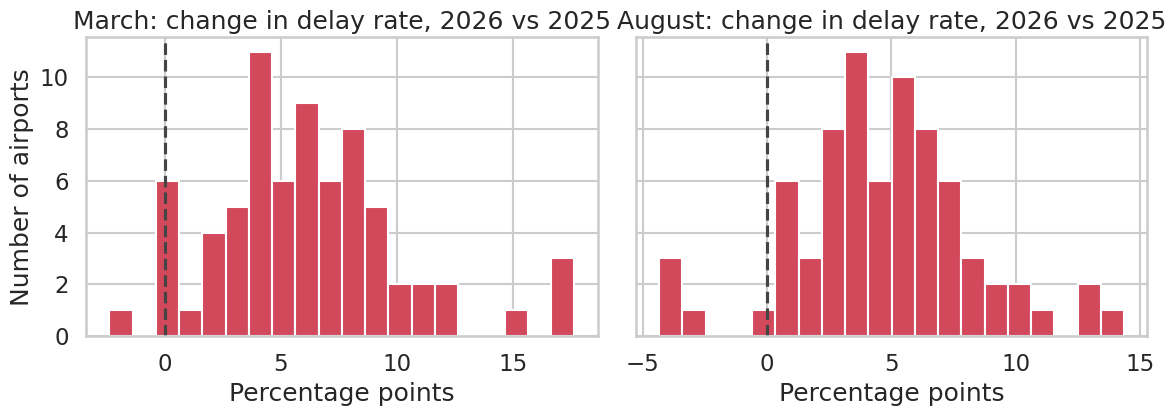

In [11]:
def airport_change(mo):
    a = daily[daily["mo"] == mo].groupby(["airport", "yr"]).agg(
        late=("late", "sum"), w=("w_valid", "sum"),
        sched=("departures_scheduled", "sum")).reset_index()
    p = a.pivot(index="airport", columns="yr", values=["late", "w", "sched"]).dropna()
    change = p[("late", 2026)] / p[("w", 2026)] - p[("late", 2025)] / p[("w", 2025)]
    return change[p[("sched", 2025)] >= 1500]   # skip tiny airports

chg = {3: airport_change(3), 8: airport_change(8)}
for mo, c in chg.items():
    print("month", mo, "| airports:", len(c), "| got worse:", (c > 0).sum(),
          "| median change:", round(c.median(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (mo, name) in zip(axes, [(3, "March"), (8, "August")]):
    ax.hist(chg[mo] * 100, bins=20, color="#d1495b")
    ax.axvline(0, color="#444", linestyle="--")
    ax.set(title=f"{name}: change in delay rate, 2026 vs 2025", xlabel="Percentage points")
axes[0].set_ylabel("Number of airports")
plt.tight_layout(); plt.savefig("figures/09_2026_vs_2025.png", dpi=200); plt.show()